In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from utc_src import config
import os



In [28]:
# display names for x tick labels
LABELS = {
    'spring': 'Spring', 'summer': 'Summer', 'fall': 'Fall',
    'spring_summer': '[Spring,Summer]', 'spring_fall': '[Spring,Fall]', 'summer_fall': '[Summer,Fall]',
    'all_seasons': '[Spring,\nSummer,Fall]',
    'all_vars': 'All\nVariables', 'medians_only': 'All Seasons', 'deltas_only': 'Deltas',
    'iqr_only': 'IQR', 'medians_deltas': 'Medians\n + Deltas', 'median_season_only': 'Growing\nSeason',
}

season_groups = ['spring', 'summer', 'fall', 'spring_summer', 'spring_fall', 'summer_fall','all_seasons','median_season_only','medians_only']

def read_in_results(output_label, features_to_plot):
    out = []
    for model_type, metric in (('clf', 'auc'), ('rgr', 'r2')):
        df = pd.read_csv(config.MODELS / output_label / f'{output_label}_{model_type}_results_ci.csv')
        # enforces rows in the same order as the tick labels
        df = df.set_index('feature_set').loc[features_to_plot].reset_index()
        out.append(df.rename(columns=lambda c: c.replace(f'_{metric}', '')))   # sameyear_auc_low -> sameyear_low
    return out  # c, r


def get_err(est, high, low):
    return np.array([est - low, high - est])


def shared_ylim(dfs, pad=0.15):
    """y-limits covering every CI in dfs, padded by `pad` x the data range on each side."""
    lo = min(df[['sameyear_low', 'otheryear_low']].min().min() for df in dfs)
    hi = max(df[['sameyear_high', 'otheryear_high']].max().max() for df in dfs)
    margin = (hi - lo) * pad
    return lo - margin, hi + margin


def plot_feature_comparison_old(output_label_1, output_label_2, year_1, year_2, features_to_plot, fname):
    c_1, r_1 = read_in_results(output_label_1, features_to_plot)
    c_2, r_2 = read_in_results(output_label_2, features_to_plot)

    colors_1 = ('#007979', '#24B1B1')
    colors_2 = ('#5FACD3', '#97DDE9')

    # one y-range per row (model type), shared by both training years so the panels compare directly
    c_ylim = shared_ylim([c_1, c_2])
    r_ylim = shared_ylim([r_1, r_2])

    result_dfs = [(c_1, f'{year_1}-trained Classifiers', c_ylim, colors_1, 'AUC'),
                  (c_2, f'{year_2}-trained Classifiers', c_ylim, colors_2, 'AUC'),
                  (r_1, f'{year_1}-trained Regressors', r_ylim, colors_1, 'R²'),
                  (r_2, f'{year_2}-trained Regressors', r_ylim, colors_2, 'R²')]

    n = len(features_to_plot)
    fig, axes = plt.subplots(2, 2, figsize=(max(9, 1.6 * n + 2), 7))   # widen with more feature sets
    axes = axes.ravel()
    x, w = np.arange(n), 0.38
    tick_labels = [LABELS.get(f, f) for f in features_to_plot]

    for i, (data, title, ylim, colors, label) in enumerate(result_dfs):
        ax = axes[i]
        ax.grid(axis='y', alpha=0.3)
        ax.bar(x - w/2, data['sameyear'], w, color=colors[0])
        ax.errorbar(x - w/2, data['sameyear'], yerr=get_err(data['sameyear'], data['sameyear_high'], data['sameyear_low']),
                    fmt='none', ecolor='0.3', elinewidth=1, capsize=4, capthick=1)
        ax.bar(x + w/2, data['otheryear'], w, color=colors[1])
        ax.errorbar(x + w/2, data['otheryear'], yerr=get_err(data['otheryear'], data['otheryear_high'], data['otheryear_low']),
                    fmt='none', ecolor='0.3', elinewidth=1, capsize=4, capthick=1)
        ax.set_ylim(*ylim)
        ax.set_title(title)
        ax.set_ylabel(label)
        ax.set_xticks(x)
        ax.set_xticklabels(tick_labels, fontsize=9)
        if i > 1:
            ax.set_xlabel('Feature Set')

    handles1 = [Patch(color=colors_1[0], label=f'{year_1}-trained, same-year test'),
                Patch(color=colors_1[1], label=f'{year_1}-trained, cross-year test')]
    handles2 = [Patch(color=colors_2[0], label=f'{year_2}-trained, same-year test'),
                Patch(color=colors_2[1], label=f'{year_2}-trained, cross-year test')]
    fig.legend(handles=handles1, loc='upper center', frameon=False, bbox_to_anchor=(0.28, 1.08))
    fig.legend(handles=handles2, loc='upper center', frameon=False, bbox_to_anchor=(0.77, 1.08))
    plt.tight_layout()

    plt.show()
    # config.FIGURES.mkdir(parents=True, exist_ok=True)
    # plt.savefig(config.FIGURES / f'feature_comparison_{fname}_{output_label_1}_{output_label_2}.png', bbox_inches='tight', dpi=300)  
   
    # plt.close()

In [31]:
def shared_lim(dfs, pad_frac=0.08):
    """One axis range covering every value and CI in `dfs`, with a little padding."""
    lo = min(min(d['sameyear_low'].min(), d['otheryear_low'].min()) for d in dfs)
    hi = max(max(d['sameyear_high'].max(), d['otheryear_high'].max()) for d in dfs)
    pad = (hi - lo) * pad_frac
    return lo - pad, hi + pad


def plot_feature_comparison(output_label_1, output_label_2, year_1, year_2, features_to_plot, fname=None):
    c_1, r_1 = read_in_results(output_label_1, features_to_plot)
    c_2, r_2 = read_in_results(output_label_2, features_to_plot)

    colors_1 = ('#007979', '#24B1B1')
    colors_2 = ('#5FACD3', '#97DDE9')

    # columns = model type (classifier | regressor); rows = training year; each column shares its x-axis
    panels = {(0, 0): (c_1, f'{year_1}-trained Classifier AUC', colors_1),
              (1, 0): (c_2, f'{year_2}-trained Classifier AUC', colors_2),
              (0, 1): (r_1, f'{year_1}-trained Regressor R²', colors_1),
              (1, 1): (r_2, f'{year_2}-trained Regressor R²', colors_2)}
    xlims = {0: shared_lim([c_1, c_2]), 1: shared_lim([r_1, r_2])}
    xlabels = {0: 'AUC', 1: 'R²'}

    n = len(features_to_plot)
    fig, axes = plt.subplots(2, 2, figsize=(10, 2 * (0.45 * n + 0.9)), sharex='col', sharey=True)
    y, h = np.arange(n)[::-1], 0.38          # first feature set at the top
    tick_labels = [LABELS.get(f, f) for f in features_to_plot]
    err_kw = dict(fmt='none', ecolor='0.3', elinewidth=1, capsize=3, capthick=1)

    for (r, c), (data, title, colors) in panels.items():
        ax = axes[r, c]
        data = data.set_index('feature_set').loc[features_to_plot]        # rows in the requested order
        ax.barh(y + h / 2, data['sameyear'], h, color=colors[0])
        ax.errorbar(data['sameyear'], y + h / 2,
                    xerr=get_err(data['sameyear'], data['sameyear_high'], data['sameyear_low']), **err_kw)
        ax.barh(y - h / 2, data['otheryear'], h, color=colors[1])
        ax.errorbar(data['otheryear'], y - h / 2,
                    xerr=get_err(data['otheryear'], data['otheryear_high'], data['otheryear_low']), **err_kw)
        ax.set_xlim(*xlims[c])
        ax.set_title(title, fontsize=12, loc='center')
        ax.grid(axis='x', alpha=0.3)
        # for s in ('top', 'right'):
        #     ax.spines[s].set_visible(False)
        if r == 1:
            ax.set_xlabel(xlabels[c])

    axes[0, 0].set_yticks(y)
    axes[0, 0].set_yticklabels(tick_labels)
    #axes[0, 0].set_ylabel('Feature set'); axes[1, 0].set_ylabel('Feature set')

    handles1 = [Patch(color=colors_1[0], label='Same-year test'),
               Patch(color=colors_1[1], label='Cross-year test')]
    handles2 =  [Patch(color=colors_2[0], label='Same-year test'),
               Patch(color=colors_2[1], label='Cross-year test')]

    axes[0,0].legend(handles=handles1)
    axes[1,0].legend(handles=handles2)
    plt.tight_layout()
    if fname:
        plt.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()

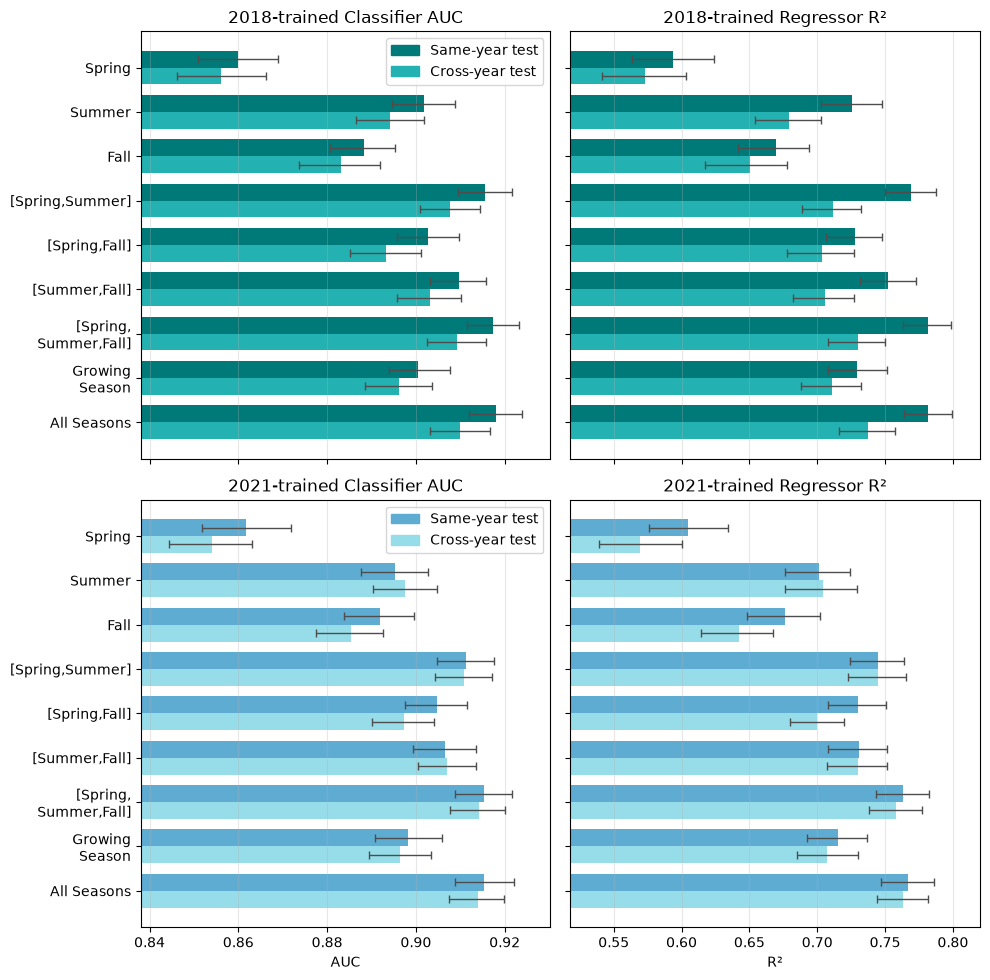

In [32]:
plot_feature_comparison(output_label_1='nyc18',year_1=2018,year_2=2021,output_label_2='nyc21',features_to_plot=season_groups,fname=None)

In [33]:
18*4

72